In [30]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import importlib
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))
import DAS_processing as DASproc
import DAS_model_inversion as DASmi
import DAS_plots as DASplt

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
import pickle

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob

import scipy
import scipy.signal as scisig
from scipy.integrate import cumulative_trapezoid
from scipy.fft import fft, ifft, fftfreq
from scipy.signal import butter, filtfilt

%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# medium parameters
vp=4291.584
vs=2407.92
rho=2600

#fracture compliance
ct_true =7e-11
cn_true=0.5*ct_true

#source location
xs=82.0
ys=3700.25882
ts=1.9096

#fiber gauge length
gl=5

In [3]:
#import scattering data

with open("./data/scattering_data.pkl", "rb") as f:
    scattering_data = pickle.load(f)

In [4]:
#frequecies

time=scattering_data['reflection_traces'].taxis
N=len(time)
dt=scattering_data['reflection_traces'].dt
freqs = fftfreq(N, d=dt)

In [5]:

#inc_wave
#geometric factor

alpha=0.5
gfactor=DASmi.geometric_factor(scattering_data,freqs,gl,vs,alpha)

#update dictionary with geometric factors
scattering_data.update({
    "Gr": gfactor["Gr"],
    "Gt": gfactor["Gt"],
    "freqs": gfactor["freqs"],
    "omega": gfactor["omega"],
})



In [ ]:
#Ricker wavelet
t0=np.max(time)/2
f0=100
#f1=75
inc_ricker = DASmi.ricker(time, t0, f0)
#inc_ricker_inv = DASmi.ricker(time, t0, f1)

inc_wave = {
    "S_omega": inc_ricker["fft"],
    "freqs": inc_ricker["freqs"],
    "time": inc_ricker["time"],
}

In [ ]:
plt.close('all')
plt.figure()
plt.plot(time,inc_ricker['trace'])
#plt.plot(time,inc_ricker_inv['trace'])
plt.xlim(0.15,0.30)
plt.show()

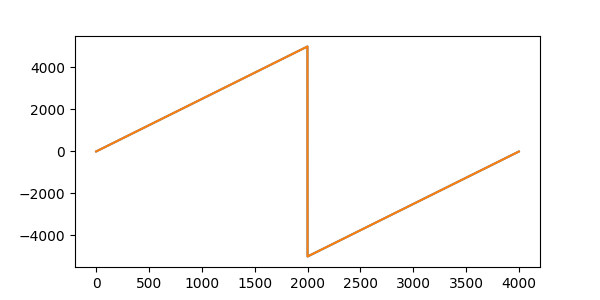

In [7]:
plt.close('all')
plt.figure(figsize=(6,3))
plt.plot(inc_ricker['freqs'])
plt.plot(freqs)
plt.show()

In [ ]:
# Creating the true data
#******************************
index=np.arange(len(scattering_data["theta_i_deg"]))

#Simulated data RT waves
RT_batch= DASmi.RT_wave_batch(
    scattering_data, inc_wave, index, vp, vs, rho, cn_true, ct_true, wave="SS")


In [ ]:
#inversion: fit R waves using source wavelet

#Estimating the Rwaves using a scaled source wavelet for the forward modeling
nsearch=(25,25)
#search_space=[(1e-14,1e-8),(1e-14,1e-8)]

search_space=[(1e-14, 1e-8), (0.01, 3.0)]

#test1: non-scaled source wavelet (scalar applied to synthetic data)
scalar1 =1

In [28]:
gsRT_time =DASmi.cnct_ratio_search_time(
    RT_batch,
    scattering_data,
    vp,
    vs,
    rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
    eta=1e-3)

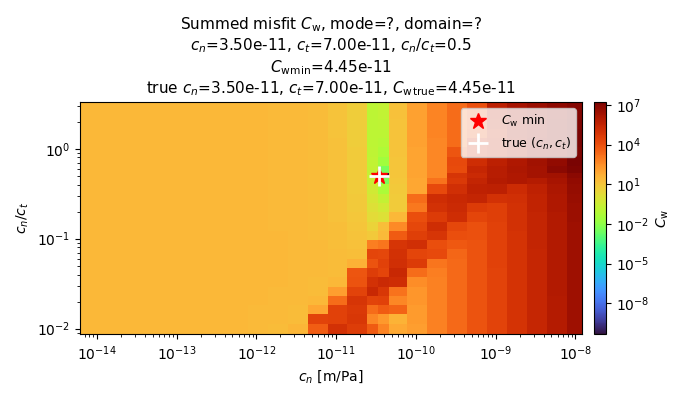

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{w}}$, mode=?, domain=?\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{w}}$$_{\\mathrm{min}}$=4.45e-11\ntrue $c_n$=3.50e-11, $c_t$=7.00e-11, $C_{\\mathrm{w}}$$_{\\mathrm{true}}$=4.45e-11'}, xlabel='$c_n$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [31]:
DASplt.plot_cost_sum(gsRT_time, figsize=(7, 4))

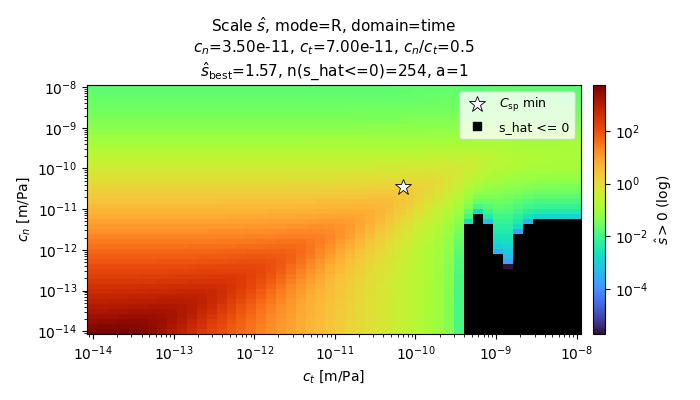

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=1.57, n(s_hat<=0)=254, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [22]:
DASplt.plot_s_hat(gsR_time1, figsize=(7, 4))

In [30]:
gsR_time1V2 = DASmi.cnct_search_RtimeV2(
    R_batch, ref_data, inc_ricker_inv, scalar1,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

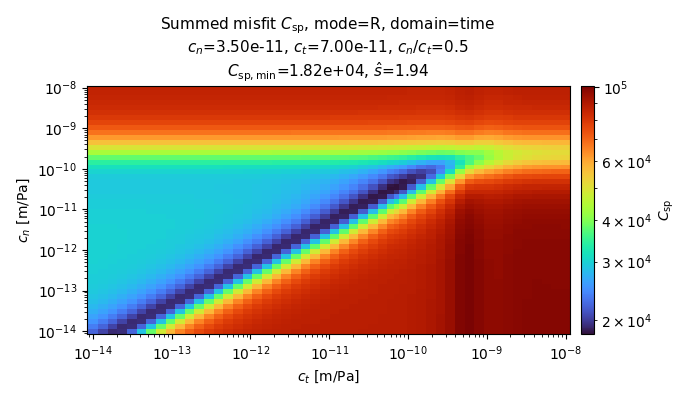

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.82e+04, $\\hat{s}$=1.94'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [32]:
DASplt.plot_cost_sum(gsR_time1V2, figsize=(7, 4))


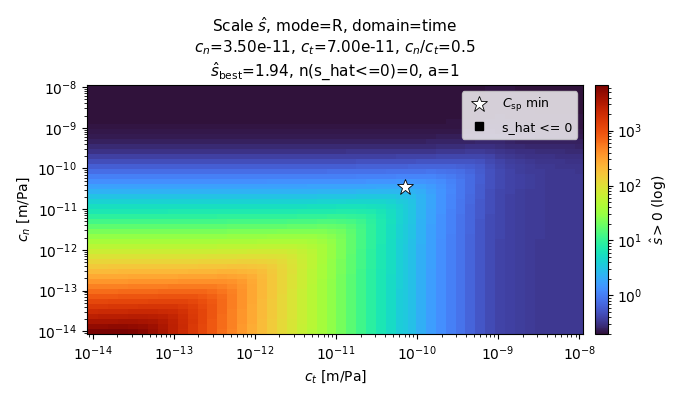

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=1.94, n(s_hat<=0)=0, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [33]:
DASplt.plot_s_hat(gsR_time1V2, figsize=(7, 4))

In [ ]:
#test2: non-scaled source wavelet (scalar applied to synthetic data)
scalar2 =5
gsR_time2 = DASmi.cnct_search_Rtime(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

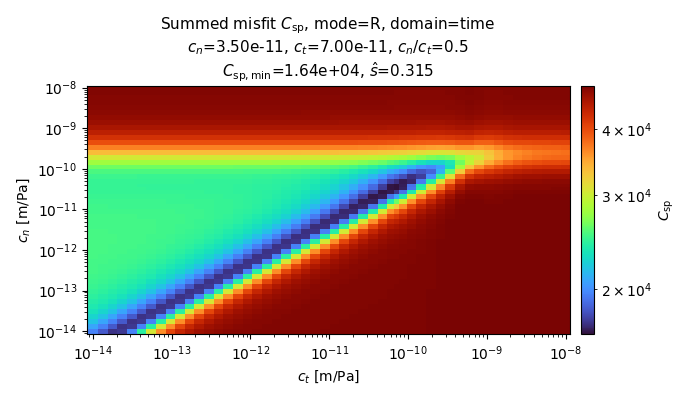

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.64e+04, $\\hat{s}$=0.315'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [25]:
DASplt.plot_cost_sum(gsR_time2, figsize=(7, 4))

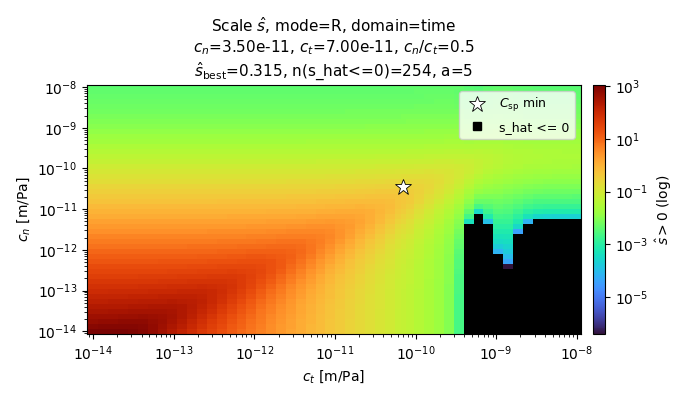

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=0.315, n(s_hat<=0)=254, a=5'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [27]:
DASplt.plot_s_hat(gsR_time2, figsize=(7, 4))

In [34]:
gsR_time2V2 = DASmi.cnct_search_RtimeV2(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

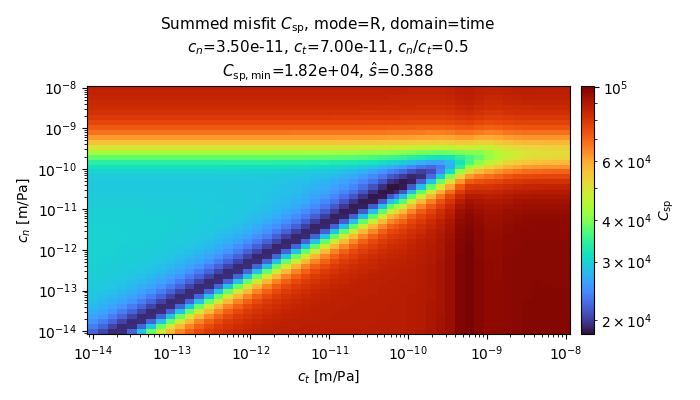

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.82e+04, $\\hat{s}$=0.388'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [35]:
DASplt.plot_cost_sum(gsR_time2V2, figsize=(7, 4))

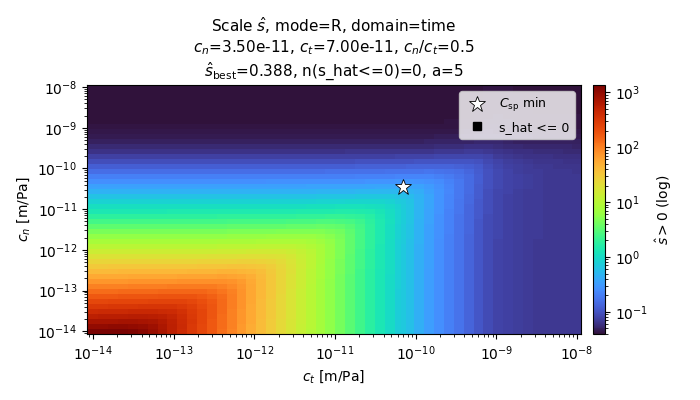

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=0.388, n(s_hat<=0)=0, a=5'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [36]:
DASplt.plot_s_hat(gsR_time2V2, figsize=(7, 4))

In [37]:
#Test1:cnct ratio
search_space11=[(0.01,3.0),(1e-14,1e-8)]
nsearch11=(50,50)

gsR_time2_ratio = DASmi.cnct_search_Rtime_ratio(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space11,
    nsearch11,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

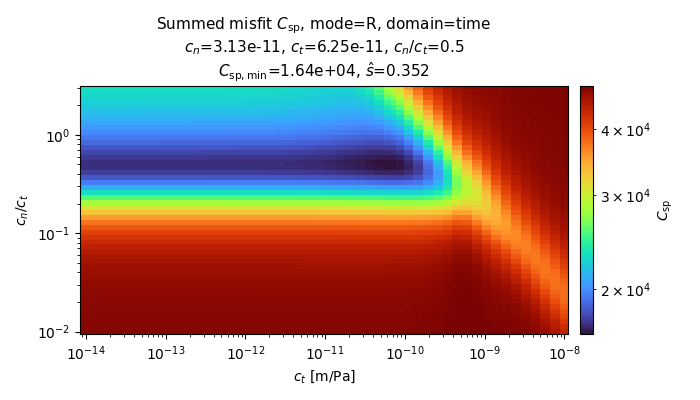

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.13e-11, $c_t$=6.25e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.64e+04, $\\hat{s}$=0.352'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [38]:
DASplt.plot_cost_sum(gsR_time2_ratio, figsize=(7, 4))